In [38]:
import yfinance as yf
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [39]:
dis = yf.download(tickers='DIS', start='2023-01-01', end='2023-03-31', rounding=True)
dis

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,DIS,DIS,DIS,DIS,DIS
Date,,,,,
2023-01-03,86.26,87.23,85.16,86.27,14997100
2023-01-04,89.18,89.93,86.64,87.26,14957200
2023-01-05,89.12,89.67,87.76,88.87,11622600
2023-01-06,91.06,91.81,88.54,89.84,9828100
2023-01-09,91.89,92.79,90.61,91.56,11675800
...,...,...,...,...,...
2023-03-24,91.22,92.11,90.19,91.92,9534600
2023-03-27,92.71,93.10,91.51,91.90,7487900


In [40]:
dis = dis["Close"]
dis

Ticker,DIS
Date,
2023-01-03,86.26
2023-01-04,89.18
2023-01-05,89.12
2023-01-06,91.06
2023-01-09,91.89
...,...
2023-03-24,91.22
2023-03-27,92.71
2023-03-28,91.93


In [73]:
dis.index = pd.to_datetime(dis.index)
len_train = int(len(dis)*0.7)
print(f"Total: {len(dis)}, Train: {len_train}, Test: {len(dis)-len_train}")

Total: 61, Train: 42, Test: 19


In [42]:
train = dis[0:len_train]
test  = dis[len_train:]
print("Entrenamiento:", len(train))
print("Prueba:", len(test))
train

Entrenamiento: 42
Prueba: 19


Ticker,DIS
Date,
2023-01-03,86.26
2023-01-04,89.18
2023-01-05,89.12
2023-01-06,91.06
2023-01-09,91.89
2023-01-10,92.65
2023-01-11,93.40
2023-01-12,96.77
2023-01-13,96.37


In [43]:
test

Ticker,DIS
Date,
2023-03-06,97.60
2023-03-07,96.04
2023-03-08,96.28
2023-03-09,93.21
2023-03-10,90.72
2023-03-13,89.78
2023-03-14,90.52
2023-03-15,90.27
2023-03-16,91.42


[ 1.          0.93347806  0.87436563  0.80454093  0.74376264  0.67300145
  0.59653853  0.51672442  0.45316675  0.37753268  0.28000844  0.18634161
  0.08303196 -0.00593506 -0.08744464 -0.1681614  -0.22724103 -0.27454904]


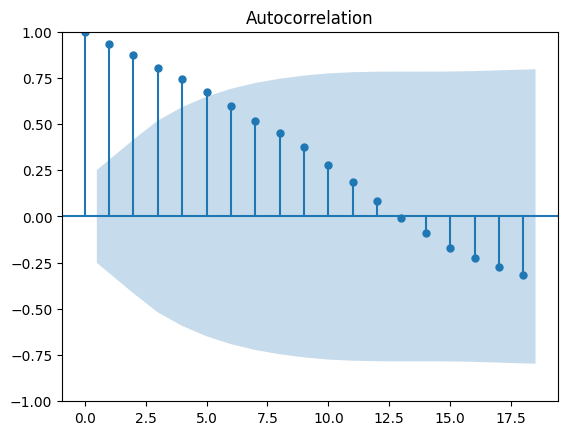

In [44]:
from statsmodels.tsa.stattools import acf
acf_array = acf(dis)
print(acf_array)
plot_acf(dis, alpha=0.05)
plt.show()

In [45]:
mod = ARIMA(train, order=(1,0,0))
res = mod.fit()

In [46]:
print(res.summary())

                               SARIMAX Results                                
Dep. Variable:                    DIS   No. Observations:                   42
Model:                 ARIMA(1, 0, 0)   Log Likelihood                 -83.733
Date:                Thu, 15 Oct 2026   AIC                            173.465
Time:                        12:42:47   BIC                            178.678
Sample:                             0   HQIC                           175.376
                                 - 42                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         95.1709      5.105     18.642      0.000      85.165     105.177
ar.L1          0.9715      0.032     30.177      0.000       0.908       1.035
sigma2         2.9471      0.654      4.506      0.0

In [47]:
predicciones = res.forecast(len(test))
predicciones

42    97.977659
43    97.897665
44    97.819951
45    97.744452
46    97.671104
47    97.599847
48    97.530621
49    97.463368
50    97.398032
51    97.334558
52    97.272892
53    97.212985
54    97.154785
55    97.098243
56    97.043313
57    96.989949
58    96.938106
59    96.887740
60    96.838809
Name: predicted_mean, dtype: float64

In [48]:
conf = res.get_forecast(len(test)).conf_int(alpha=0.10)
conf

,lower DIS,upper DIS
42,95.153903,100.801415
43,93.960768,101.834562
44,93.065809,102.574093
45,92.330998,103.157905
46,91.701815,103.640393
47,91.149743,104.049951
48,90.657504,104.403738
49,90.213613,104.713123
50,89.809930,104.986133
51,89.440412,105.228703


In [49]:
fcast_res = res.get_forecast(len(test))
print(fcast_res.summary_frame(alpha=0.10))

DIS       mean   mean_se  mean_ci_lower  mean_ci_upper
42   97.977659  1.716722      95.153903     100.801415
43   97.897665  2.393464      93.960768     101.834562
44   97.819951  2.890313      93.065809     102.574093
45   97.744452  3.291146      92.330998     103.157905
46   97.671104  3.629070      91.701815     103.640393
47   97.599847  3.921385      91.149743     104.049951
48   97.530621  4.178558      90.657504     104.403738
49   97.463368  4.407538      90.213613     104.713123
50   97.398032  4.613238      89.809930     104.986133
51   97.334558  4.799299      89.440412     105.228703
52   97.272892  4.968519      89.100406     105.445379
53   97.212985  5.123105      88.786227     105.639743
54   97.154785  5.264843      88.494888     105.814682
55   97.098243  5.395203      88.223924     105.972563
56   97.043313  5.515412      87.971268     106.115359
57   96.989949  5.626511      87.735161     106.244737
58   96.938106  5.729392      87.514094     106.362117
59   96.88

In [50]:
test = pd.DataFrame(test)
predicciones = pd.DataFrame(predicciones)
test = test.reset_index()
predicciones = predicciones.reset_index()

In [51]:
predicciones

,index,predicted_mean
0,42,97.977659
1,43,97.897665
2,44,97.819951
3,45,97.744452
4,46,97.671104
5,47,97.599847
6,48,97.530621
7,49,97.463368
8,50,97.398032
9,51,97.334558


In [52]:
test

Ticker,Date,DIS
0,2023-03-06,97.60
1,2023-03-07,96.04
2,2023-03-08,96.28
3,2023-03-09,93.21
4,2023-03-10,90.72
5,2023-03-13,89.78
6,2023-03-14,90.52
7,2023-03-15,90.27
8,2023-03-16,91.42
9,2023-03-17,90.36


In [53]:
# Cálculo correcto de métricas comparando el test real con las predicciones
test_values = test['DIS'].values
pred_values = predicciones['predicted_mean'].values

mse = np.mean((test_values - pred_values) ** 2)
rmse = np.round(np.sqrt(mse), 2)
mape = np.round(np.mean(np.abs((test_values - pred_values) / test_values)) * 100, 2)

print("MSE:", mse)
print("RMSE:", rmse)
print("MAPE:", mape, "%")

MSE: 26.448400037463415
RMSE: 5.14
MAPE: 5.11 %


In [54]:
predicciones_ext = res.forecast(len(test)+5)
predicciones_ext.tail(5)

61    96.791274
62    96.745093
63    96.700228
64    96.656642
65    96.614298
Name: predicted_mean, dtype: float64

In [55]:
conf_ext = res.get_forecast(len(test)+5).conf_int(alpha=0.10)
conf_ext.tail(5)

,lower DIS,upper DIS
61,86.928799,106.653748
62,86.756273,106.733913
63,86.593610,106.806846
64,86.440091,106.873192
65,86.295065,106.933530


In [56]:
train = pd.DataFrame(train)
lista = test["Date"]
lista = pd.DataFrame(lista)
test.index = test["Date"]
test.drop(columns=["Date"], inplace=True)
test

Ticker,DIS
Date,
2023-03-06,97.60
2023-03-07,96.04
2023-03-08,96.28
2023-03-09,93.21
2023-03-10,90.72
2023-03-13,89.78
2023-03-14,90.52
2023-03-15,90.27
2023-03-16,91.42


In [57]:
lista

,Date
0,2023-03-06
1,2023-03-07
2,2023-03-08
3,2023-03-09
4,2023-03-10
5,2023-03-13
6,2023-03-14
7,2023-03-15
8,2023-03-16
9,2023-03-17


In [58]:
import pandas as pd

k = 21  # días hábiles de Abril 2023
lista2 = []

for day in range(1, k + 1):
    fecha = (pd.to_datetime("2023-03-31") + pd.offsets.BDay(day)).date()
    lista2.append(fecha)

lista2 = pd.DataFrame(lista2, columns=["Date"])
lista2["Date"] = pd.to_datetime(lista2["Date"])

# Concatenar ambos DataFrames
fecha = pd.concat([lista, lista2], ignore_index=True)
fecha

,Date
0,2023-03-06
1,2023-03-07
2,2023-03-08
3,2023-03-09
4,2023-03-10
5,2023-03-13
6,2023-03-14
7,2023-03-15
8,2023-03-16
9,2023-03-17


In [59]:
fecha = pd.concat([lista, lista2])
fecha = fecha.reset_index(drop=True)
fecha

,Date
0,2023-03-06
1,2023-03-07
2,2023-03-08
3,2023-03-09
4,2023-03-10
5,2023-03-13
6,2023-03-14
7,2023-03-15
8,2023-03-16
9,2023-03-17


In [60]:
predicciones = res.forecast(len(test) + k)
predicciones = pd.DataFrame(predicciones)
predicciones = predicciones.reset_index()
predicciones

,index,predicted_mean
0,42,97.977659
1,43,97.897665
2,44,97.819951
3,45,97.744452
4,46,97.671104
5,47,97.599847
6,48,97.530621
7,49,97.463368
8,50,97.398032
9,51,97.334558


In [61]:
predicciones.drop(columns=["index"], inplace=True)
predicciones

,predicted_mean
0,97.977659
1,97.897665
2,97.819951
3,97.744452
4,97.671104
5,97.599847
6,97.530621
7,97.463368
8,97.398032
9,97.334558


In [62]:
frames = [fecha, predicciones]
result = pd.concat(frames, axis=1, join='inner')
result.columns = ['Date', 'Predicciones']
result

,Date,Predicciones
0,2023-03-06,97.977659
1,2023-03-07,97.897665
2,2023-03-08,97.819951
3,2023-03-09,97.744452
4,2023-03-10,97.671104
5,2023-03-13,97.599847
6,2023-03-14,97.530621
7,2023-03-15,97.463368
8,2023-03-16,97.398032
9,2023-03-17,97.334558


In [63]:
print(result.dtypes)

Date            datetime64[ns]
Predicciones           float64
dtype: object


In [64]:
result.index = result['Date']
result.drop(columns=["Date"], inplace=True)
result

,Predicciones
Date,
2023-03-06,97.977659
2023-03-07,97.897665
2023-03-08,97.819951
2023-03-09,97.744452
2023-03-10,97.671104
2023-03-13,97.599847
2023-03-14,97.530621
2023-03-15,97.463368
2023-03-16,97.398032


In [65]:
conf = res.get_forecast(len(test) + k).conf_int(alpha=0.10)
conf = conf.reset_index()
conf.drop(columns=["index"], inplace=True)
conf

,lower DIS,upper DIS
0,95.153903,100.801415
1,93.960768,101.834562
2,93.065809,102.574093
3,92.330998,103.157905
4,91.701815,103.640393
5,91.149743,104.049951
6,90.657504,104.403738
7,90.213613,104.713123
8,89.809930,104.986133
9,89.440412,105.228703


In [66]:
frames = [fecha, conf]
intervalos = pd.concat(frames, axis=1, join='inner')
intervalos

,Date,lower DIS,upper DIS
0,2023-03-06,95.153903,100.801415
1,2023-03-07,93.960768,101.834562
2,2023-03-08,93.065809,102.574093
3,2023-03-09,92.330998,103.157905
4,2023-03-10,91.701815,103.640393
5,2023-03-13,91.149743,104.049951
6,2023-03-14,90.657504,104.403738
7,2023-03-15,90.213613,104.713123
8,2023-03-16,89.809930,104.986133
9,2023-03-17,89.440412,105.228703


In [67]:
intervalos.index = intervalos['Date']
intervalos.drop(columns=["Date"], inplace=True)
intervalos

,lower DIS,upper DIS
Date,,
2023-03-06,95.153903,100.801415
2023-03-07,93.960768,101.834562
2023-03-08,93.065809,102.574093
2023-03-09,92.330998,103.157905
2023-03-10,91.701815,103.640393
2023-03-13,91.149743,104.049951
2023-03-14,90.657504,104.403738
2023-03-15,90.213613,104.713123
2023-03-16,89.809930,104.986133


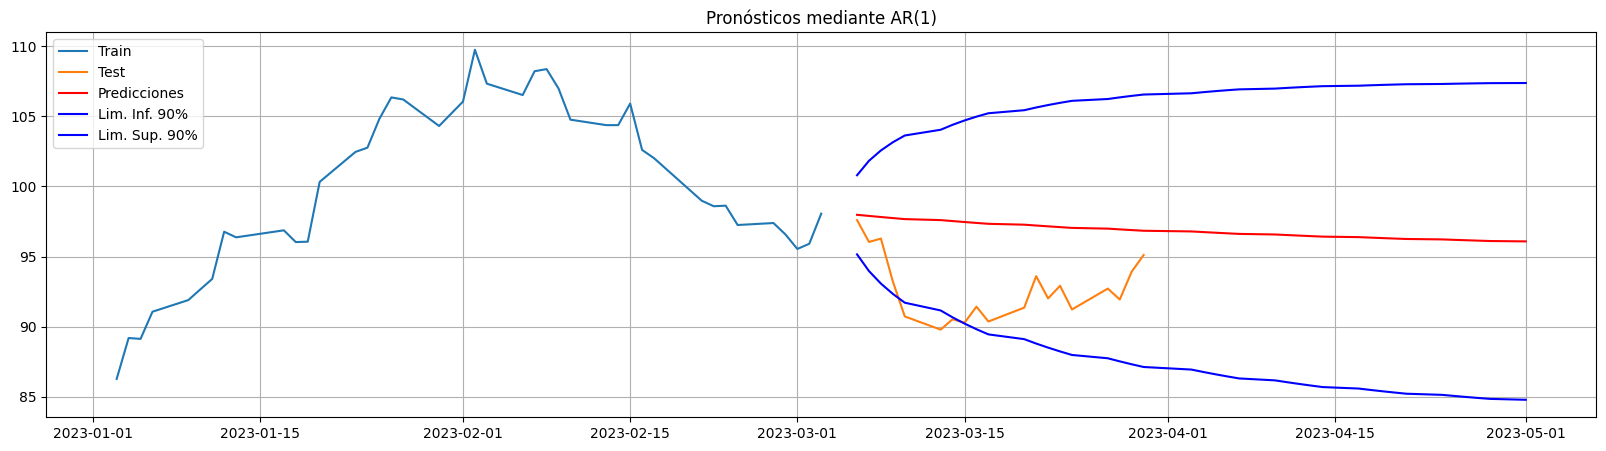

In [68]:
plt.figure(figsize=(20,5))
plt.grid()
plt.plot(train, label="Train")
plt.plot(test, label="Test")
plt.plot(result, label="Predicciones", color="red")
plt.plot(intervalos['lower DIS'], label="Lim. Inf. 90%", color="blue")
plt.plot(intervalos['upper DIS'], label="Lim. Sup. 90%", color="blue")
plt.legend(loc="best")
plt.title("Pronósticos mediante AR(1)")
plt.show()

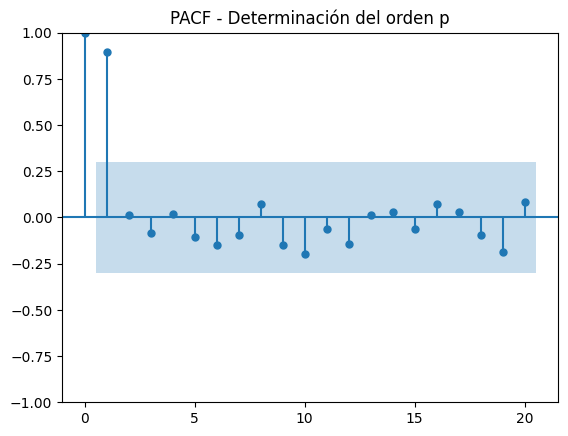

In [69]:
from statsmodels.graphics.tsaplots import plot_pacf
plot_pacf(train, lags=20)
plt.title("PACF - Determinación del orden p")
plt.show()

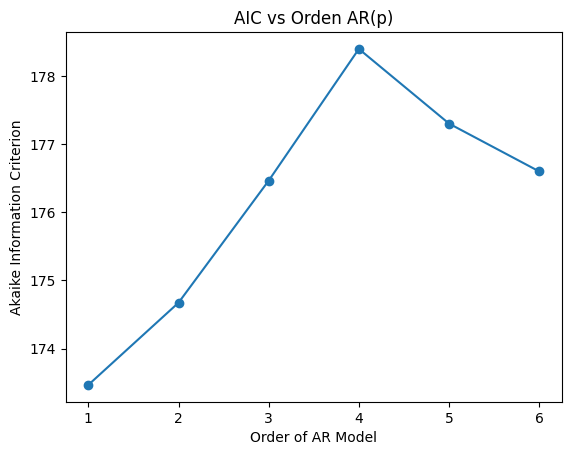

In [70]:
AIC = np.zeros(7)
for p in range(7):
    mod = ARIMA(train, order=(p,0,0))
    res = mod.fit()
    AIC[p] = res.aic

plt.plot(range(1,7), AIC[1:7], marker='o')
plt.xlabel('Order of AR Model')
plt.ylabel('Akaike Information Criterion')
plt.title('AIC vs Orden AR(p)')
plt.show()

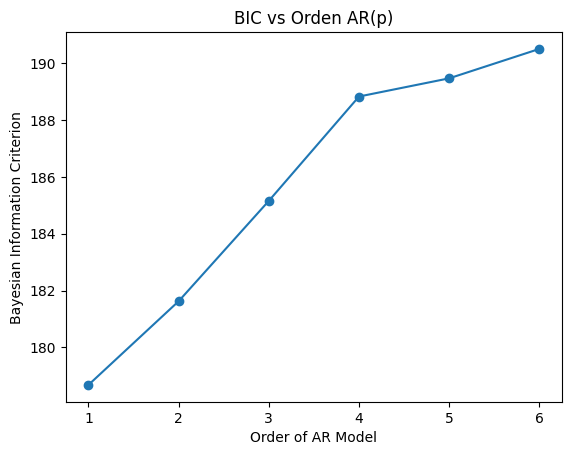

In [71]:
BIC = np.zeros(7)
for p in range(7):
    mod = ARIMA(train, order=(p,0,0))
    res = mod.fit()
    BIC[p] = res.bic

plt.plot(range(1,7), BIC[1:7], marker='o')
plt.xlabel('Order of AR Model')
plt.ylabel('Bayesian Information Criterion')
plt.title('BIC vs Orden AR(p)')
plt.show()

In [72]:
print("AIC:", AIC[1:7])
print("BIC:", BIC[1:7])
best_p_aic = np.argmin(AIC[1:7]) + 1
best_p_bic = np.argmin(BIC[1:7]) + 1
print("Mejor p según AIC:", best_p_aic)
print("Mejor p según BIC:", best_p_bic)

AIC: [173.46513394 174.67298422 176.46678892 178.40216611 177.30485219
 176.60199912]
BIC: [178.67814279 181.62366269 185.15513701 188.82818382 189.46853952
 190.50335606]
Mejor p según AIC: 1
Mejor p según BIC: 1
